# Orvosi és Laikus Szövegek Osztályozása
Összesített notebook: Adattisztítás, Naiv Bayes, Logisztikus Regresszió, SVM, Random Forest és Összehasonlítás.

In [10]:
!pip install pandas numpy scikit-learn matplotlib seaborn -q

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score

In [11]:
# Adatok beolvasása és mondatpárok kinyerése
with open("data.json", "r", encoding="utf-8") as f:
    data = json.load(f)

rows = []
def process_data(obj, path=[]):
    if isinstance(obj, dict):
        if "abstract" in obj and "adaptations" in obj:
            article_id = path[-1]
            title = obj.get("Title", "")
            abstract = obj.get("abstract", {})
            adaptations = obj.get("adaptations", {})
            for adaptation_name, adaptation in adaptations.items():
                for sentence_id, original_text in abstract.items():
                    if sentence_id in adaptation:
                        rows.append({
                            "article_id": article_id,
                            "title": title,
                            "sentence_id": sentence_id,
                            "original": original_text,
                            "simplified": adaptation[sentence_id],
                            "adaptation": adaptation_name
                        })
        for key, value in obj.items():
            process_data(value, path + [key])

process_data(data)
df = pd.DataFrame(rows)
print(f"Kinyert sorok száma: {len(df)}")
ml_df = df[["original", "simplified"]].copy()

Kinyert sorok száma: 9319


In [12]:
# 1. Üres sorok törlése
ml_df["original"] = ml_df["original"].astype(str).str.strip()
ml_df["simplified"] = ml_df["simplified"].astype(str).str.strip()
ml_df = ml_df[(ml_df["original"] != "") & (ml_df["simplified"] != "")].reset_index(drop=True)

# 2. Pontos duplikátumok törlése
ml_df = ml_df.drop_duplicates().reset_index(drop=True)

# 3. Közel-duplikátumok törlése (TF-IDF + Cosine Similarity)
szovegek = ml_df["original"].tolist()
vectorizer = TfidfVectorizer(lowercase=True, stop_words="english")
tfidf_matrix = vectorizer.fit_transform(szovegek)
similarity_matrix = cosine_similarity(tfidf_matrix)
np.fill_diagonal(similarity_matrix, 0)

kuszob = 0.85
torlendo_indexek = set()
for i in range(len(ml_df)):
    for j in range(i + 1, len(ml_df)):
        if similarity_matrix[i, j] >= kuszob:
            torlendo_indexek.add(j) # Mindig a későbbi sort jelöljük törlésre

ml_df = ml_df.drop(index=list(torlendo_indexek)).reset_index(drop=True)
print(f"Tisztítás után maradt sorok száma: {len(ml_df)}")

Tisztítás után maradt sorok száma: 7432


In [13]:
# Adatelőkészítés az osztályozáshoz és TF-IDF Vektorizálás
original_df = pd.DataFrame({'text': ml_df['original'], 'label': 1})
simplified_df = pd.DataFrame({'text': ml_df['simplified'], 'label': 0})
class_df = pd.concat([original_df, simplified_df], ignore_index=True)

X_train_text, X_test_text, y_train, y_test = train_test_split(
    class_df['text'], class_df['label'], test_size=0.2, random_state=42, stratify=class_df['label']
)

tfidf = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)
print(f"Tanító halmaz mérete: {X_train_tfidf.shape}")
print(f"Teszt halmaz mérete: {X_test_tfidf.shape}")

Tanító halmaz mérete: (11891, 15000)
Teszt halmaz mérete: (2973, 15000)


In [14]:
# 1. Naiv Bayes modell betanítása és kiértékelése
nb_classifier = MultinomialNB(alpha=1.0)
nb_classifier.fit(X_train_tfidf, y_train)
y_pred_nb = nb_classifier.predict(X_test_tfidf)

acc_nb = accuracy_score(y_test, y_pred_nb)
f1_nb = f1_score(y_test, y_pred_nb)
print("Naiv Bayes Eredmények:")
print(f"Accuracy: {acc_nb:.4f}, F1-score: {f1_nb:.4f}\n")

Naiv Bayes Eredmények:
Accuracy: 0.7619, F1-score: 0.7631



In [15]:
# 2. Logisztikus Regresszió modell betanítása és kiértékelése
lr_classifier = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
lr_classifier.fit(X_train_tfidf, y_train)
y_pred_lr = lr_classifier.predict(X_test_tfidf)

acc_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
print("Logisztikus Regresszió Eredmények:")
print(f"Accuracy: {acc_lr:.4f}, F1-score: {f1_lr:.4f}\n")

Logisztikus Regresszió Eredmények:
Accuracy: 0.7894, F1-score: 0.7954



In [16]:
# 3. SVM (Support Vector Machine) modell betanítása és kiértékelése
# A lineáris kernel különösen jól teljesít magas dimenziójú szöveges adatok (TF-IDF) esetén.
svm_classifier = SVC(kernel='linear', C=1.0, random_state=42)
svm_classifier.fit(X_train_tfidf, y_train)
y_pred_svm = svm_classifier.predict(X_test_tfidf)

acc_svm = accuracy_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
print("SVM Eredmények:")
print(f"Accuracy: {acc_svm:.4f}, F1-score: {f1_svm:.4f}\n")

SVM Eredmények:
Accuracy: 0.7793, F1-score: 0.7838



In [17]:
# 4. Random Forest modell betanítása és kiértékelése
# A Random Forest döntési fák sokaságára épít. Több fa (n_estimators) robusztusabb eredményt ad.
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_classifier.fit(X_train_tfidf, y_train)
y_pred_rf = rf_classifier.predict(X_test_tfidf)

acc_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
print("Random Forest Eredmények:")
print(f"Accuracy: {acc_rf:.4f}, F1-score: {f1_rf:.4f}\n")

Random Forest Eredmények:
Accuracy: 0.7033, F1-score: 0.6907



,Modell,Accuracy,F1-score
0,Naiv Bayes,0.761857,0.763052
1,Logisztikus Regr.,0.789438,0.795425
2,SVM (Lineáris),0.779347,0.783784
3,Random Forest,0.703330,0.690743


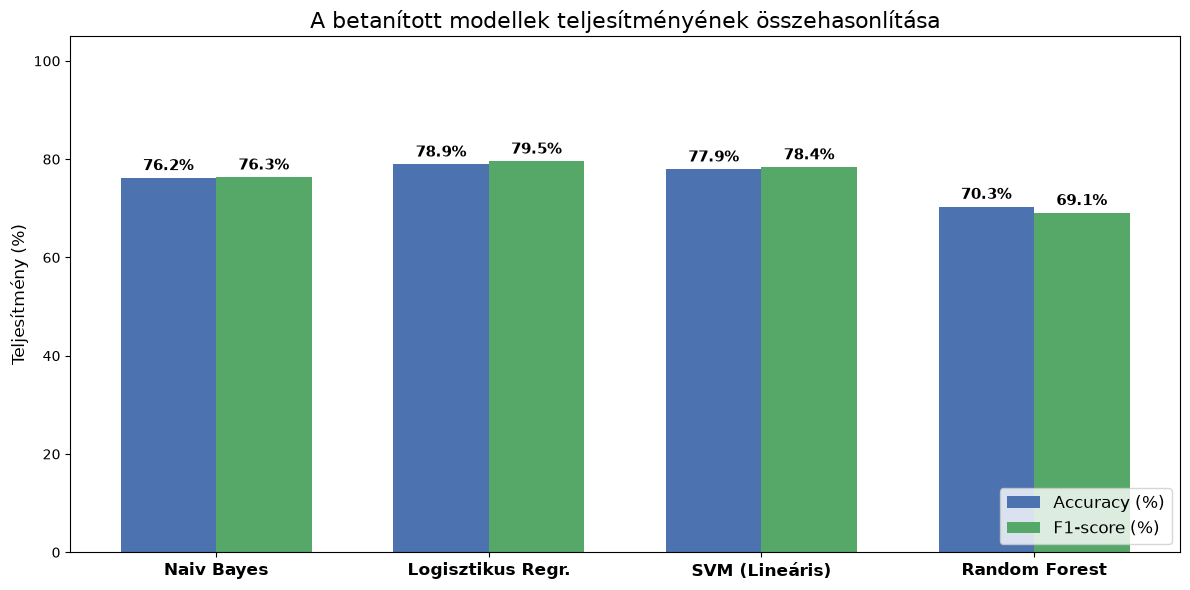

In [18]:
# Modellek teljesítményének összehasonlítása ábrán
eredmenyek = [
    {"Modell": "Naiv Bayes", "Accuracy": acc_nb, "F1-score": f1_nb},
    {"Modell": "Logisztikus Regr.", "Accuracy": acc_lr, "F1-score": f1_lr},
    {"Modell": "SVM (Lineáris)", "Accuracy": acc_svm, "F1-score": f1_svm},
    {"Modell": "Random Forest", "Accuracy": acc_rf, "F1-score": f1_rf}
]

df_osszehasonlitas = pd.DataFrame(eredmenyek)
display(df_osszehasonlitas)

x = np.arange(len(df_osszehasonlitas["Modell"]))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width/2, df_osszehasonlitas["Accuracy"] * 100, width, label='Accuracy (%)', color='#4C72B0')
rects2 = ax.bar(x + width/2, df_osszehasonlitas["F1-score"] * 100, width, label='F1-score (%)', color='#55A868')

ax.set_ylabel('Teljesítmény (%)', fontsize=12)
ax.set_title('A betanított modellek teljesítményének összehasonlítása', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(df_osszehasonlitas["Modell"], fontsize=12, fontweight='bold')
ax.set_ylim(0, 105)
ax.legend(fontsize=12, loc='lower right')

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

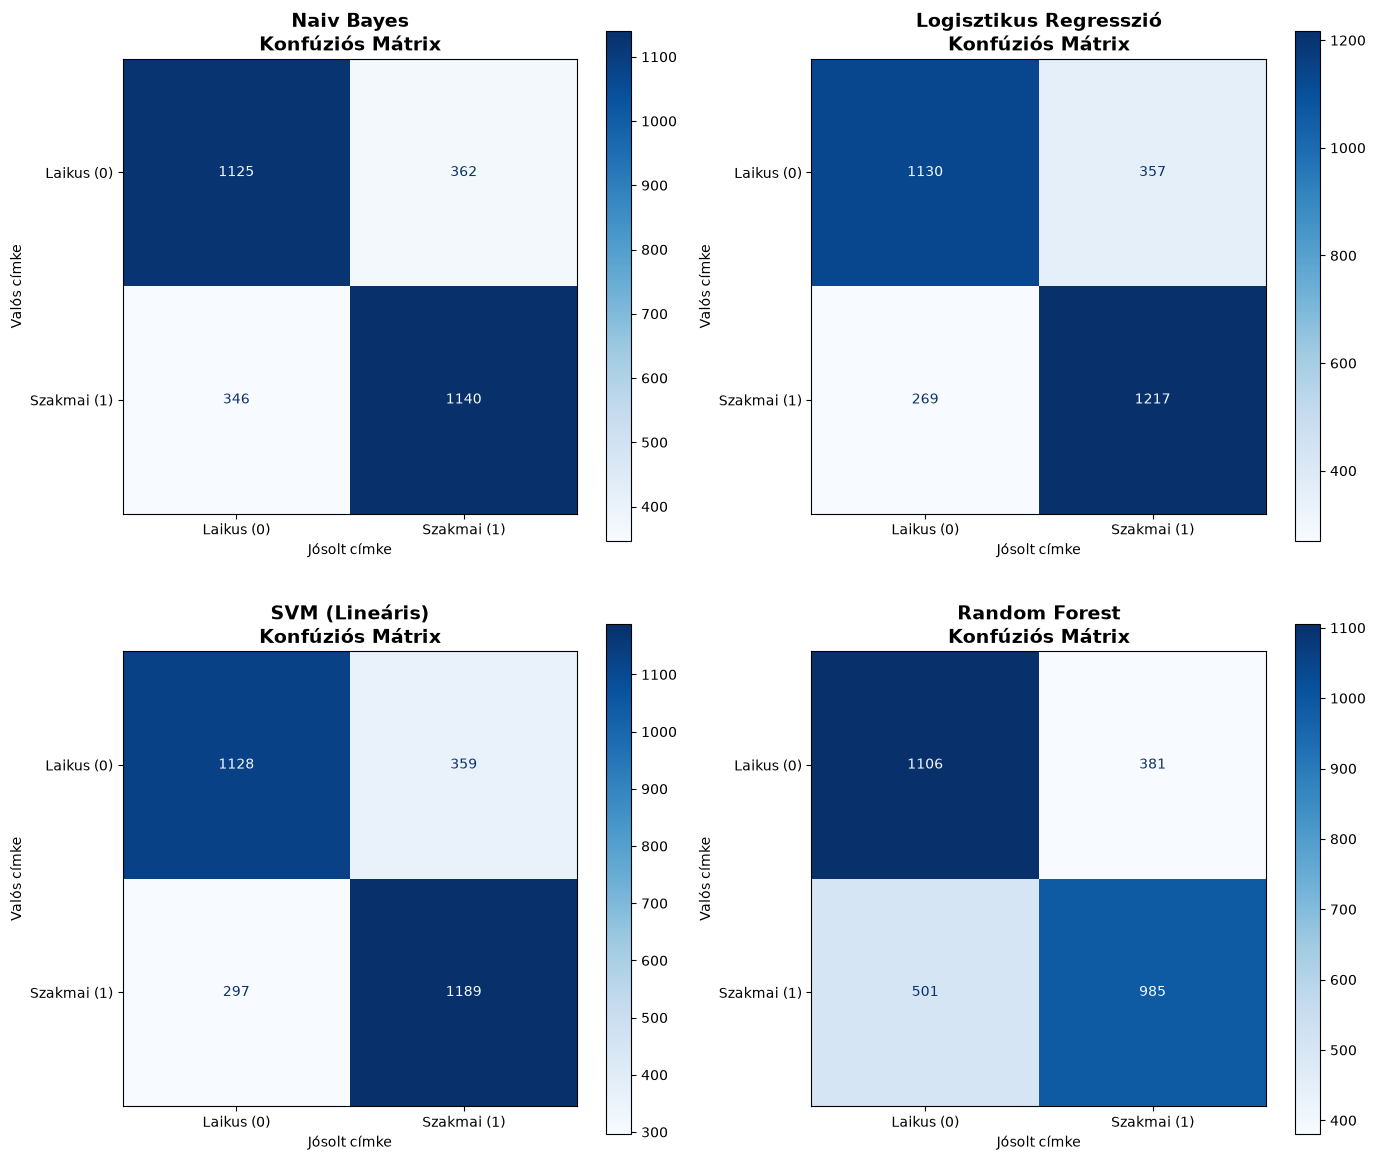

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 2x2-es ábrarács létrehozása
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten() # 1D tömbbé alakítjuk a könnyebb iterációhoz

# Modellek és a hozzájuk tartozó predikciók párosítása
modellek = [
    ("Naiv Bayes", y_pred_nb),
    ("Logisztikus Regresszió", y_pred_lr),
    ("SVM (Lineáris)", y_pred_svm),
    ("Random Forest", y_pred_rf)
]

# Konfúziós mátrixok kirajzolása egy ciklus segítségével
for i, (nev, y_pred) in enumerate(modellek):
    ConfusionMatrixDisplay.from_predictions(
        y_test, 
        y_pred, 
        display_labels=['Laikus (0)', 'Szakmai (1)'],
        cmap='Blues', 
        ax=axes[i],
        values_format='d'
    )
    axes[i].set_title(f'{nev}\nKonfúziós Mátrix', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Jósolt címke')
    axes[i].set_ylabel('Valós címke')

# Térközök optimalizálása, hogy ne fedjék egymást a feliratok
plt.tight_layout()
plt.show()